# Experiment 8: Query Processing on Large Datasets Using Apache Hive

**Aim:** To perform SQL-like querying, aggregation, and analysis of large datasets using Apache Hive.

**Mapped CO(s):** CO2

**Dataset:** Titanic Dataset (`Titanic-Dataset.csv`, 891 passengers)

## 1. Import Required Libraries

In [1]:
import os
import re
import shutil
import subprocess
import time
from io import StringIO
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Apache Hive (Brief Theory)

Apache Hive is a **data warehouse system on top of Hadoop**. Users write **HiveQL** (SQL-like), and Hive converts each query into MapReduce (or Tez/Spark) jobs that read data from HDFS.

**Hive architecture**

| Component | Role |
|---|---|
| **Beeline / CLI** | Client used to submit HiveQL statements |
| **HiveServer2** | Accepts client connections over JDBC (embedded inside Beeline in this lab) |
| **Driver** (compiler, optimizer, executor) | Parses HiveQL, builds an execution plan, and runs it as MapReduce jobs |
| **Metastore** | Stores table schemas and HDFS locations (here an embedded **Derby** database) |
| **HDFS** | Stores the actual table data under `/user/hive/warehouse` |

**Common HiveQL operations**

| Statement | Purpose |
|---|---|
| `CREATE DATABASE` | Create a new database |
| `CREATE TABLE` | Define a table schema (columns, row format, storage) |
| `LOAD DATA INPATH` | Move a file from HDFS into a table |
| `SELECT ... WHERE` | Retrieve and filter rows |
| `GROUP BY` | Group rows for aggregation |
| `ORDER BY` | Sort the final result |
| `COUNT()`, `AVG()`, `MAX()`, `MIN()` | Aggregate functions |

Hive uses **schema-on-read**. The file stays as plain text in HDFS, and the schema is applied when the data is queried.

## 3. Set Java, Hadoop and Hive Environment

HDFS runs on Java 17. Hive 4.2.1 is compiled for Java 21, so the `beeline` and `schematool` launchers run with Java 21.

In [2]:
EXP_DIR = Path("/Users/ojas/Desktop/DS Lab/Experiment8")
SRC_DIR = EXP_DIR / "src"
DATASET = Path("/Users/ojas/Desktop/DS Lab/Shared/Titanic-Dataset.csv")

WORK_DIR = Path("/tmp/exp8")
BIN_DIR = WORK_DIR / "bin"
LOCAL_DIR = WORK_DIR / "local"
HDFS_DATA = WORK_DIR / "hdfs-data"
CONF_DIR = WORK_DIR / "hadoop-conf"
HIVE_CONF = WORK_DIR / "hive-conf"
METASTORE = WORK_DIR / "metastore_db"
LOG_DIR = WORK_DIR / "logs"

JAVA_HOME = Path("/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home")
JAVA21_HOME = Path("/opt/homebrew/opt/openjdk@21/libexec/openjdk.jdk/Contents/Home")
HADOOP_HOME = Path("/Users/ojas/hadoop-3.4.1")
HIVE_HOME = Path("/Users/ojas/apache-hive-4.2.1-bin")

os.environ["JAVA_HOME"] = str(JAVA_HOME)
os.environ["HADOOP_HOME"] = str(HADOOP_HOME)
os.environ["HADOOP_CONF_DIR"] = str(CONF_DIR)
os.environ["HADOOP_LOG_DIR"] = str(LOG_DIR)
os.environ["HIVE_HOME"] = str(HIVE_HOME)
os.environ["HIVE_CONF_DIR"] = str(HIVE_CONF)
os.environ["HADOOP_CLIENT_OPTS"] = "-Dorg.jline.terminal.provider=dumb"
os.environ["PATH"] = (
    f"{BIN_DIR}:{JAVA_HOME / 'bin'}:{HADOOP_HOME / 'bin'}:{HADOOP_HOME / 'sbin'}:"
    + os.environ["PATH"]
)

for folder in (BIN_DIR, LOCAL_DIR, LOG_DIR, HIVE_CONF):
    folder.mkdir(parents=True, exist_ok=True)

for tool in ("beeline", "schematool"):
    launcher = BIN_DIR / tool
    launcher.write_text(
        "#!/bin/bash\n"
        f'export JAVA_HOME="{JAVA21_HOME}"\n'
        f'exec "{HIVE_HOME}/bin/{tool}" "$@"\n'
    )
    launcher.chmod(0o755)


NOISE = ("NativeCodeLoader", "log4j", "WARN ", " INFO ", "SLF4J")


def clean(text):
    return "\n".join(
        line for line in (text or "").splitlines()
        if not any(word in line for word in NOISE)
    ).strip()


def capture(cmd, check=True):
    result = subprocess.run(
        cmd, shell=True, text=True, capture_output=True, env=os.environ.copy(),
        cwd=WORK_DIR, stdin=subprocess.DEVNULL,
    )
    if check and result.returncode != 0:
        print(result.stdout[-3000:])
        print(result.stderr[-4000:])
        raise RuntimeError(f"Command failed with exit code {result.returncode}: {cmd}")
    return result


def run(cmd, check=True):
    print(f"$ {cmd}")
    result = capture(cmd, check)
    for text in (clean(result.stdout), clean(result.stderr)):
        if text:
            print(text)


run("java -version")
print()
run("hadoop version | head -1")
print()
run("beeline --version")

$ java -version
openjdk version "17.0.19" 2026-04-21
OpenJDK Runtime Environment Homebrew (build 17.0.19+0)
OpenJDK 64-Bit Server VM Homebrew (build 17.0.19+0, mixed mode, sharing)

$ hadoop version | head -1


Hadoop 3.4.1

$ beeline --version


Hive 4.2.1
Git git://WK339Y174N/Users/saihemanth/upstream/hive -r 0f4761a83b40a279560359fa611a65774e42324b
Compiled by saihemanth on Wed Jul 29 11:09:50 PDT 2026
From source with checksum 683f69348d1c339bd7e2f96e13c3e55d


## 4. Start Hadoop (HDFS)

Single-node setup: `fs.defaultFS = hdfs://localhost:8020`, replication = 1. Hive's MapReduce jobs run with the local job runner and read/write HDFS.

In [3]:
if CONF_DIR.exists():
    shutil.rmtree(CONF_DIR)
shutil.copytree(HADOOP_HOME / "etc" / "hadoop", CONF_DIR)

(CONF_DIR / "core-site.xml").write_text("""<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property>
    <name>fs.defaultFS</name>
    <value>hdfs://localhost:8020</value>
  </property>
</configuration>
""")

(CONF_DIR / "hdfs-site.xml").write_text(f"""<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property><name>dfs.replication</name><value>1</value></property>
  <property><name>dfs.namenode.name.dir</name><value>file://{HDFS_DATA / 'namenode'}</value></property>
  <property><name>dfs.datanode.data.dir</name><value>file://{HDFS_DATA / 'datanode'}</value></property>
  <property><name>dfs.namenode.http-address</name><value>localhost:9870</value></property>
  <property><name>dfs.datanode.address</name><value>localhost:9866</value></property>
  <property><name>dfs.datanode.http.address</name><value>localhost:9864</value></property>
  <property><name>dfs.datanode.ipc.address</name><value>localhost:9867</value></property>
  <property><name>dfs.permissions.enabled</name><value>false</value></property>
</configuration>
""")

(CONF_DIR / "mapred-site.xml").write_text("""<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property>
    <name>mapreduce.framework.name</name>
    <value>local</value>
  </property>
</configuration>
""")

capture("hdfs --daemon stop datanode", check=False)
capture("hdfs --daemon stop namenode", check=False)
time.sleep(2)
if HDFS_DATA.exists():
    shutil.rmtree(HDFS_DATA)
HDFS_DATA.mkdir(parents=True)

capture("hdfs namenode -format -force -nonInteractive")
print("NameNode formatted.")
run("hdfs --daemon start namenode")
run("hdfs --daemon start datanode")

for _ in range(30):
    time.sleep(1)
    report = capture("hdfs dfsadmin -report", check=False)
    if "Live datanodes (1)" in report.stdout:
        break

run("jps")

NameNode formatted.
$ hdfs --daemon start namenode


$ hdfs --daemon start datanode


$ jps
24940 DataNode
24989 Jps
24877 NameNode


## 5. Configure Hive and Initialize the Metastore

`hive-site.xml` sets an embedded Derby metastore, the HDFS warehouse directory, and the MapReduce execution engine. `schematool -initSchema` creates the metastore tables.

In [4]:
(HIVE_CONF / "hive-site.xml").write_text(f"""<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property><name>javax.jdo.option.ConnectionURL</name><value>jdbc:derby:;databaseName={METASTORE};create=true</value></property>
  <property><name>hive.metastore.warehouse.dir</name><value>/user/hive/warehouse</value></property>
  <property><name>hive.metastore.schema.verification</name><value>false</value></property>
  <property><name>hive.execution.engine</name><value>mr</value></property>
  <property><name>hive.server2.enable.doAs</name><value>false</value></property>
  <property><name>hive.exec.scratchdir</name><value>/tmp/hive-scratch</value></property>
  <property><name>hive.exec.local.scratchdir</name><value>{WORK_DIR / 'local-scratch'}</value></property>
  <property><name>hive.downloaded.resources.dir</name><value>{WORK_DIR / 'resources'}</value></property>
  <property><name>hive.querylog.location</name><value>{WORK_DIR / 'querylog'}</value></property>
  <property><name>hive.stats.autogather</name><value>false</value></property>
  <property><name>hive.resultset.use.unique.column.names</name><value>false</value></property>
  <property><name>hive.auto.convert.join</name><value>false</value></property>
</configuration>
""")

if METASTORE.exists():
    shutil.rmtree(METASTORE)
result = capture("schematool -dbType derby -initSchema")
print("\n".join(l for l in result.stdout.splitlines() if "Initialization script" in l))

run("hdfs dfs -mkdir -p /user/hive/warehouse /tmp/hive-scratch")
run("hdfs dfs -chmod -R 777 /tmp/hive-scratch")

Initialization script hive-schema-4.2.0.derby.sql
Initialization script completed
$ hdfs dfs -mkdir -p /user/hive/warehouse /tmp/hive-scratch


$ hdfs dfs -chmod -R 777 /tmp/hive-scratch


## 6. Store the Titanic Dataset in HDFS

In [5]:
shutil.copy2(DATASET, LOCAL_DIR / DATASET.name)

run("hdfs dfs -mkdir -p /user/lab8/titanic")
run(f"hdfs dfs -put -f {LOCAL_DIR / DATASET.name} /user/lab8/titanic/")
run("hdfs dfs -ls /user/lab8/titanic")
print()
run("hdfs dfs -cat /user/lab8/titanic/Titanic-Dataset.csv | head -4")

$ hdfs dfs -mkdir -p /user/lab8/titanic


$ hdfs dfs -put -f /tmp/exp8/local/Titanic-Dataset.csv /user/lab8/titanic/


$ hdfs dfs -ls /user/lab8/titanic


Found 1 items
-rw-r--r--   1 ojas supergroup      60302 2026-10-09 12:38 /user/lab8/titanic/Titanic-Dataset.csv

$ hdfs dfs -cat /user/lab8/titanic/Titanic-Dataset.csv | head -4


PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.25,,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38,1,0,PC 17599,71.2833,C85,C


## 7. HiveQL Helper Functions

- `statements(sql)` removes `--` comments and splits a script into statements.
- `hive_script(sql)` runs DDL statements (CREATE / LOAD) with `beeline` and prints each statement plus the MapReduce jobs it launched.
- `hive_query(sql)` runs one `SELECT` and returns the result as a pandas DataFrame.

Beeline connects with `jdbc:hive2://` (embedded HiveServer2), so no separate server process is needed.

In [6]:
BEELINE = "beeline -u jdbc:hive2:// -n ojas --silent=true --outputformat=tsv2"
JOB_LINES = ("Total jobs", "Launching Job", "Ended Job")


def statements(sql):
    body = "\n".join(l for l in sql.splitlines() if not l.strip().startswith("--"))
    return [s.strip() for s in body.split(";") if s.strip()]


def beeline(stmts):
    script = " ".join(s + ";" for s in stmts)
    result = capture(f"{BEELINE} -e {sh_quote(script)}")
    failures = [l for l in result.stderr.splitlines() if re.match(r"^(Error: |FAILED: )", l)]
    if failures:
        print("\n".join(failures))
        raise RuntimeError("Hive statement failed")
    return result


def sh_quote(text):
    return "'" + text.replace("'", "'\\''") + "'"


def hive_script(sql, db=None):
    stmts = statements(sql)
    for s in stmts:
        print("hive>", " ".join(s.split())[:110] + (" ..." if len(" ".join(s.split())) > 110 else ""))
    result = beeline(([f"USE {db}"] if db else []) + stmts)
    jobs = [l.split(": ")[-1] if "]: " in l else l for l in result.stderr.splitlines() if any(k in l for k in JOB_LINES)]
    if jobs:
        print("\n" + "\n".join(jobs))
    print("\nOK")


def hive_query(sql, db="titanic_db", show_sql=True):
    stmt = statements(sql)[0]
    if show_sql:
        print("hive>", stmt, "\n")
    result = beeline([f"USE {db}", stmt])
    return pd.read_csv(StringIO(result.stdout), sep="\t", na_values=["NULL"], keep_default_na=False)

## 8. Create the Database and Table, and Load the Dataset

`create_titanic.hql`:

1. Creates the database `titanic_db`.
2. Creates a staging table `titanic_raw` with **OpenCSVSerde**, because passenger names contain commas inside quotes.
3. Loads the CSV from HDFS with `LOAD DATA INPATH`.
4. Creates the typed table `titanic` (INT/DOUBLE columns, ORC format) with `CREATE TABLE ... AS SELECT`. Empty ages become `NULL`.

In [7]:
create_sql = (SRC_DIR / "create_titanic.hql").read_text()
print(create_sql)

-- Experiment 8: create the Hive database and Titanic tables, then load the dataset from HDFS

-- 1. Create a database
CREATE DATABASE IF NOT EXISTS titanic_db;
USE titanic_db;

DROP TABLE IF EXISTS titanic;
DROP TABLE IF EXISTS titanic_raw;

-- 2. Staging table: OpenCSVSerde understands quoted fields such as "Braund, Mr. Owen Harris"
CREATE TABLE titanic_raw (
    PassengerId STRING, Survived STRING, Pclass STRING, Name STRING, Sex STRING,
    Age STRING, SibSp STRING, Parch STRING, Ticket STRING, Fare STRING,
    Cabin STRING, Embarked STRING
)
ROW FORMAT SERDE 'org.apache.hadoop.hive.serde2.OpenCSVSerde'
WITH SERDEPROPERTIES ("separatorChar" = ",", "quoteChar" = "\"")
STORED AS TEXTFILE
TBLPROPERTIES ("skip.header.line.count" = "1");

-- 3. Load the dataset from HDFS into the staging table
LOAD DATA INPATH '/user/lab8/titanic/Titanic-Dataset.csv' INTO TABLE titanic_raw;

-- 4. Typed table used for analysis (empty Age/Cabin/Embarked become NULL).
--    The WHERE clause drops the CSV 

In [8]:
hive_script(create_sql)

hive> CREATE DATABASE IF NOT EXISTS titanic_db
hive> USE titanic_db
hive> DROP TABLE IF EXISTS titanic
hive> DROP TABLE IF EXISTS titanic_raw
hive> CREATE TABLE titanic_raw ( PassengerId STRING, Survived STRING, Pclass STRING, Name STRING, Sex STRING, Age ST ...
hive> LOAD DATA INPATH '/user/lab8/titanic/Titanic-Dataset.csv' INTO TABLE titanic_raw
hive> CREATE TABLE titanic STORED AS ORC AS SELECT CAST(PassengerId AS INT) AS passengerid, CAST(Survived AS INT) AS ...



Total jobs = 1
Launching Job 1 out of 1
Ended Job = job_local1919577503_0001

OK


### Verify: databases, tables, schema, and warehouse location in HDFS

In [9]:
display(hive_query("SHOW DATABASES", db="default"))
display(hive_query("SHOW TABLES"))
display(hive_query("DESCRIBE titanic"))
run("hdfs dfs -ls /user/hive/warehouse/titanic_db.db")

hive> SHOW DATABASES 



,database_name
0,default
1,titanic_db


hive> SHOW TABLES 



,tab_name
0,titanic
1,titanic_raw


hive> DESCRIBE titanic 



,col_name,data_type,comment
0,passengerid,int,
1,survived,int,
2,pclass,int,
3,name,string,
4,sex,string,
5,age,double,
6,sibsp,int,
7,parch,int,
8,ticket,string,
9,fare,double,


$ hdfs dfs -ls /user/hive/warehouse/titanic_db.db


Found 2 items
drwxr-xr-x   - ojas supergroup          0 2026-10-09 12:38 /user/hive/warehouse/titanic_db.db/titanic
drwxr-xr-x   - ojas supergroup          0 2026-10-09 12:38 /user/hive/warehouse/titanic_db.db/titanic_raw


## 9. Display the Table Contents (SELECT)

In [10]:
display(hive_query("SELECT * FROM titanic LIMIT 10"))

hive> SELECT * FROM titanic LIMIT 10 



,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [11]:
display(hive_query("SELECT COUNT(*) AS total_passengers FROM titanic"))

hive> SELECT COUNT(*) AS total_passengers FROM titanic 



,total_passengers
0,891


## 10. Filtering (WHERE)

In [12]:
seniors = hive_query("""
SELECT passengerid, name, sex, pclass, age, survived
FROM titanic
WHERE age >= 65
ORDER BY age DESC
""")
display(seniors)
print("Passengers aged 65 or more:", len(seniors))

hive> SELECT passengerid, name, sex, pclass, age, survived
FROM titanic
WHERE age >= 65
ORDER BY age DESC 



,passengerid,name,sex,pclass,age,survived
0,631,"Barkworth, Mr. Algernon Henry Wilson",male,1,80.0,1
1,852,"Svensson, Mr. Johan",male,3,74.0,0
2,494,"Artagaveytia, Mr. Ramon",male,1,71.0,0
3,97,"Goldschmidt, Mr. George B",male,1,71.0,0
4,117,"Connors, Mr. Patrick",male,3,70.5,0
5,746,"Crosby, Capt. Edward Gifford",male,1,70.0,0
6,673,"Mitchell, Mr. Henry Michael",male,2,70.0,0
7,34,"Wheadon, Mr. Edward H",male,2,66.0,0
8,457,"Millet, Mr. Francis Davis",male,1,65.0,0
9,281,"Duane, Mr. Frank",male,3,65.0,0


Passengers aged 65 or more: 11


## 11. Grouping and Aggregation (GROUP BY, COUNT, AVG)

In [13]:
class_stats = hive_query("""
SELECT pclass,
       COUNT(*)                     AS passengers,
       SUM(survived)                AS survived,
       ROUND(AVG(survived) * 100, 2) AS survival_pct,
       ROUND(AVG(age), 2)           AS avg_age,
       ROUND(AVG(fare), 2)          AS avg_fare
FROM titanic
GROUP BY pclass
ORDER BY pclass
""")
display(class_stats)

hive> SELECT pclass,
       COUNT(*)                     AS passengers,
       SUM(survived)                AS survived,
       ROUND(AVG(survived) * 100, 2) AS survival_pct,
       ROUND(AVG(age), 2)           AS avg_age,
       ROUND(AVG(fare), 2)          AS avg_fare
FROM titanic
GROUP BY pclass
ORDER BY pclass 



,pclass,passengers,survived,survival_pct,avg_age,avg_fare
0,1,216,136,62.96,38.23,84.15
1,2,184,87,47.28,29.88,20.66
2,3,491,119,24.24,25.14,13.68


hive> SELECT sex, COUNT(*) AS passengers, SUM(survived) AS survived,
       ROUND(AVG(survived) * 100, 2) AS survival_pct
FROM titanic
GROUP BY sex
ORDER BY survival_pct DESC 



,sex,passengers,survived,survival_pct
0,female,314,233,74.20
1,male,577,109,18.89


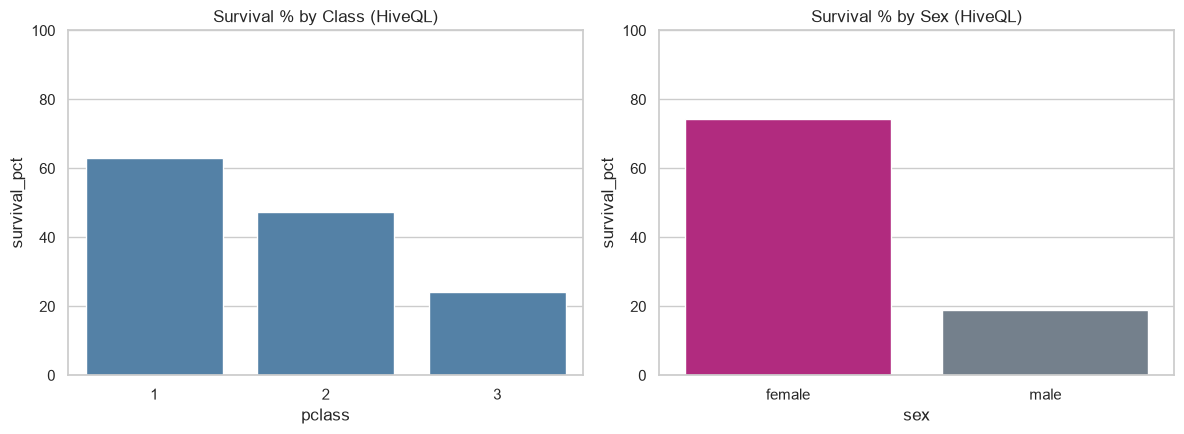

In [14]:
sex_stats = hive_query("""
SELECT sex, COUNT(*) AS passengers, SUM(survived) AS survived,
       ROUND(AVG(survived) * 100, 2) AS survival_pct
FROM titanic
GROUP BY sex
ORDER BY survival_pct DESC
""")
display(sex_stats)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=class_stats, x="pclass", y="survival_pct", ax=axes[0], color="steelblue")
axes[0].set_title("Survival % by Class (HiveQL)")
sns.barplot(data=sex_stats, x="sex", y="survival_pct", ax=axes[1], palette=["mediumvioletred", "slategray"], hue="sex", legend=False)
axes[1].set_title("Survival % by Sex (HiveQL)")
for ax in axes:
    ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

## 12. Sorting (ORDER BY) and Embarkation Port Analysis

In [15]:
port_stats = hive_query("""
SELECT embarked, COUNT(*) AS passengers, ROUND(AVG(fare), 2) AS avg_fare
FROM titanic
WHERE embarked IS NOT NULL
GROUP BY embarked
ORDER BY passengers DESC
""")
port_stats["port"] = port_stats["embarked"].map({"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"})
display(port_stats)

hive> SELECT embarked, COUNT(*) AS passengers, ROUND(AVG(fare), 2) AS avg_fare
FROM titanic
WHERE embarked IS NOT NULL
GROUP BY embarked
ORDER BY passengers DESC 



,embarked,passengers,avg_fare,port
0,S,644,27.08,Southampton
1,C,168,59.95,Cherbourg
2,Q,77,13.28,Queenstown


### Cross-check with pandas

In [16]:
df = pd.read_csv(DATASET)
check = df.groupby("Pclass").agg(
    passengers=("PassengerId", "count"),
    survived=("Survived", "sum"),
    avg_fare=("Fare", "mean"),
).round(2).reset_index()
display(check)
print("Hive and pandas results match:",
      class_stats[["passengers", "survived", "avg_fare"]].equals(check[["passengers", "survived", "avg_fare"]]))

,Pclass,passengers,survived,avg_fare
0,1,216,136,84.15
1,2,184,87,20.66
2,3,491,119,13.68


Hive and pandas results match: True


---
## Exercises / Assignments

All exercise queries are saved in `exercises.hql`. Each one is run separately below.

In [17]:
exercise_sql = (SRC_DIR / "exercises.hql").read_text()
print(exercise_sql)
EX = [s for s in statements(exercise_sql) if not s.upper().startswith("USE")]

-- Experiment 8 exercises (HiveQL on titanic_db.titanic)
USE titanic_db;

-- Exercise 1: display only female passengers
SELECT passengerid, name, pclass, age, fare, survived
FROM titanic
WHERE sex = 'female'
ORDER BY passengerid;

-- Exercise 2: average fare for each passenger class
SELECT pclass, COUNT(*) AS passengers, ROUND(AVG(fare), 2) AS avg_fare
FROM titanic
GROUP BY pclass
ORDER BY pclass;

-- Exercise 3: number of passengers who survived
SELECT COUNT(*) AS survived_passengers
FROM titanic
WHERE survived = 1;

-- Exercise 4: passengers sorted by age (descending, unknown ages excluded)
SELECT passengerid, name, sex, pclass, age
FROM titanic
WHERE age IS NOT NULL
ORDER BY age DESC, passengerid ASC;

-- Exercise 5: maximum and minimum fare
SELECT MAX(fare) AS max_fare, MIN(fare) AS min_fare
FROM titanic;



### Exercise 1: Display only female passengers

In [18]:
females = hive_query(EX[0])
print("Female passengers:", len(females))
display(females.head(10))

hive> SELECT passengerid, name, pclass, age, fare, survived
FROM titanic
WHERE sex = 'female'
ORDER BY passengerid 



Female passengers: 314


,passengerid,name,pclass,age,fare,survived
0,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,71.2833,1
1,3,"Heikkinen, Miss. Laina",3,26.0,7.9250,1
2,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,53.1000,1
3,9,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",3,27.0,11.1333,1
4,10,"Nasser, Mrs. Nicholas (Adele Achem)",2,14.0,30.0708,1
5,11,"Sandstrom, Miss. Marguerite Rut",3,4.0,16.7000,1
6,12,"Bonnell, Miss. Elizabeth",1,58.0,26.5500,1
7,15,"Vestrom, Miss. Hulda Amanda Adolfina",3,14.0,7.8542,0
8,16,"Hewlett, Mrs. (Mary D Kingcome)",2,55.0,16.0000,1
9,19,"Vander Planke, Mrs. Julius (Emelia Maria Vande...",3,31.0,18.0000,0


`WHERE sex = 'female'` returns **314** of the 891 passengers.

### Exercise 2: Find the average fare for each passenger class

hive> SELECT pclass, COUNT(*) AS passengers, ROUND(AVG(fare), 2) AS avg_fare
FROM titanic
GROUP BY pclass
ORDER BY pclass 



,pclass,passengers,avg_fare
0,1,216,84.15
1,2,184,20.66
2,3,491,13.68


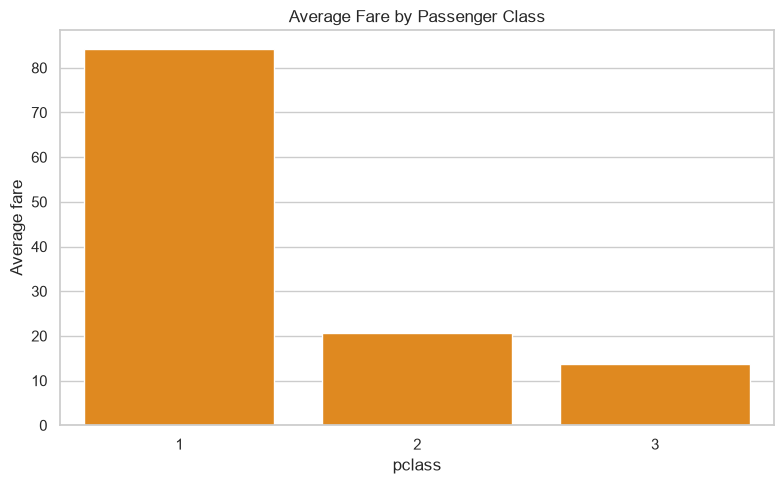

In [19]:
avg_fare = hive_query(EX[1])
display(avg_fare)

sns.barplot(data=avg_fare, x="pclass", y="avg_fare", color="darkorange")
plt.title("Average Fare by Passenger Class")
plt.ylabel("Average fare")
plt.tight_layout()
plt.show()

1st class paid about **84.15** on average, roughly 4 times the 2nd-class fare (**20.66**) and 6 times the 3rd-class fare (**13.68**).

### Exercise 3: Count the number of passengers who survived

In [20]:
survived = hive_query(EX[2])
display(survived)
total = len(df)
n = int(survived.iloc[0, 0])
print(f"Survived: {n} of {total} ({n / total:.2%})")

hive> SELECT COUNT(*) AS survived_passengers
FROM titanic
WHERE survived = 1 



,survived_passengers
0,342


Survived: 342 of 891 (38.38%)


**342** passengers survived, a survival rate of 38.38%.

### Exercise 4: Sort passengers by age in descending order

In [21]:
by_age = hive_query(EX[3])
print("Passengers with a known age:", len(by_age))
print("Oldest 10:")
display(by_age.head(10))
print("Youngest 5:")
display(by_age.tail(5))

hive> SELECT passengerid, name, sex, pclass, age
FROM titanic
WHERE age IS NOT NULL
ORDER BY age DESC, passengerid ASC 



Passengers with a known age: 714
Oldest 10:


,passengerid,name,sex,pclass,age
0,631,"Barkworth, Mr. Algernon Henry Wilson",male,1,80.0
1,852,"Svensson, Mr. Johan",male,3,74.0
2,97,"Goldschmidt, Mr. George B",male,1,71.0
3,494,"Artagaveytia, Mr. Ramon",male,1,71.0
4,117,"Connors, Mr. Patrick",male,3,70.5
5,673,"Mitchell, Mr. Henry Michael",male,2,70.0
6,746,"Crosby, Capt. Edward Gifford",male,1,70.0
7,34,"Wheadon, Mr. Edward H",male,2,66.0
8,55,"Ostby, Mr. Engelhart Cornelius",male,1,65.0
9,281,"Duane, Mr. Frank",male,3,65.0


Youngest 5:


,passengerid,name,sex,pclass,age
709,832,"Richards, Master. George Sibley",male,2,0.83
710,470,"Baclini, Miss. Helene Barbara",female,3,0.75
711,645,"Baclini, Miss. Eugenie",female,3,0.75
712,756,"Hamalainen, Master. Viljo",male,2,0.67
713,804,"Thomas, Master. Assad Alexander",male,3,0.42


177 passengers have no age recorded, so `WHERE age IS NOT NULL` keeps 714 rows. The oldest passenger is 80 (Barkworth, Mr. Algernon Henry Wilson), and the youngest is an infant aged 0.42.

### Exercise 5: Find the maximum and minimum fare using HiveQL

In [22]:
fare_range = hive_query(EX[4])
display(fare_range)

who = hive_query("""
SELECT passengerid, name, pclass, fare
FROM titanic
WHERE fare = (SELECT MAX(fare) FROM titanic) OR fare = 0
ORDER BY fare DESC, passengerid
""")
display(who)

hive> SELECT MAX(fare) AS max_fare, MIN(fare) AS min_fare
FROM titanic 



,max_fare,min_fare
0,512.3292,0.0


hive> SELECT passengerid, name, pclass, fare
FROM titanic
WHERE fare = (SELECT MAX(fare) FROM titanic) OR fare = 0
ORDER BY fare DESC, passengerid 



,passengerid,name,pclass,fare
0,259,"Ward, Miss. Anna",1,512.3292
1,680,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292
2,738,"Lesurer, Mr. Gustave J",1,512.3292
3,180,"Leonard, Mr. Lionel",3,0.0000
4,264,"Harrison, Mr. William",1,0.0000
5,272,"Tornquist, Mr. William Henry",3,0.0000
6,278,"Parkes, Mr. Francis ""Frank""",2,0.0000
7,303,"Johnson, Mr. William Cahoone Jr",3,0.0000
8,414,"Cunningham, Mr. Alfred Fleming",2,0.0000
9,467,"Campbell, Mr. William",2,0.0000


The maximum fare is **512.33** (three 1st-class passengers), and the minimum fare is **0.0** (15 passengers, most likely crew or complimentary tickets).

---
## Observation

- The Hive database `titanic_db` and the tables `titanic_raw` / `titanic` were created successfully.
- The Titanic dataset was loaded from HDFS into the Hive table (891 rows).
- SQL-like queries (`SELECT`, `WHERE`, `GROUP BY`, `ORDER BY`) were executed successfully. Hive ran aggregations as MapReduce jobs.
- `COUNT` and `AVG` produced the expected results: 342 survivors, and average fares of 84.15 / 20.66 / 13.68 for classes 1 / 2 / 3.
- The results matched an independent pandas calculation.

## Result

Apache Hive successfully processed and analyzed the Titanic dataset using SQL-like queries. Query execution and aggregation operations demonstrated Hive's capability to analyze large datasets efficiently.

## Conclusion

The experiment demonstrated how Apache Hive provides a simple SQL-like interface for querying and analyzing large datasets stored in Hadoop. HiveQL made it easy to perform filtering, grouping, sorting, and aggregation operations, making Hive an effective tool for big data analytics.